# Modeling the pupillometric signal

**WARNING**: This functionality is **experimental**. Some of the provided algorithms are unpublished (or in the process of being published) and may not work well.

The idea behind the algorithms is detailed in this notebook (slides from a symposium talk):

- [Estimation of tonic and phasic pupillometric signals](symp_talk_uit2019.ipynb)

This notebook also includes results from a simulation study showing the advantage of the algorithm over more traditional approaches.

In [1]:
import pypillometry as pp
from pypillometry import u
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats

It can be useful to think about the pupillometric signal as being composed of different components. One common assumption, based on the finding that the pupil reflects activity in the norepinephrinergic system, is that it consists of slow, tonic (baseline) and faster, phasic (response) fluctuations.

To illustrate this, we simulate data according to such a model: event-induced responses are superimposed on a slow, baseline-like component. The response to each event is a scaled version of a "response kernel" (Hoeks & Levelt, 1993), which can be plotted with `pp.plot_prf()`:

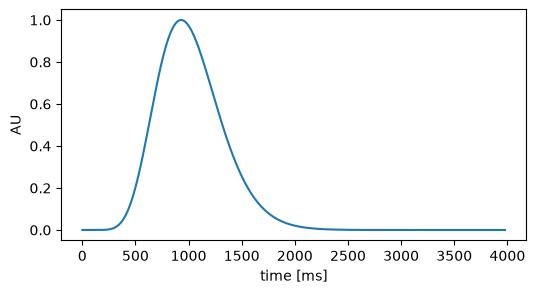

In [2]:
plt.figure(figsize=(6, 3))
pp.plot_prf(npar=10.1, tmax=930)

We create 100 events with random inter-stimulus intervals between 0.6 and 1.4 seconds (a "fast" paradigm in which the responses to successive events overlap), a slowly fluctuating baseline (`pp.fake_pupil_baseline()`), a response of random amplitude to each event (using the design matrix from `pp.pupil_build_design_matrix()`) and some measurement noise:

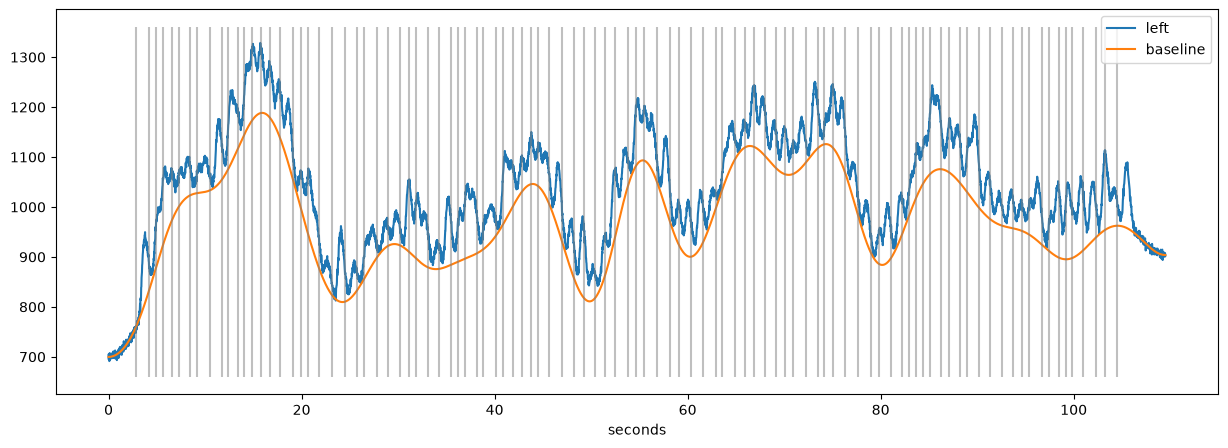

In [3]:
rng = np.random.default_rng(12)
fs = 50       # sampling rate (Hz)
ntrials = 100

event_onsets = 2000 + np.cumsum(rng.uniform(600, 1400, ntrials))  # in ms
duration = event_onsets[-1] + 5000                                   # in ms

# time (ms) and baseline
tx, real_baseline, _ = pp.fake_pupil_baseline(duration/1000, fs, mean=1000, amplitude=100,
                                              freq=0.1, seed=12)
X = pp.pupil_build_design_matrix(tx, event_onsets, fs, npar=10.1, tmax=930)
real_response_coef = rng.uniform(50, 150, ntrials)
real_response = real_response_coef @ X
noise = rng.normal(0, 5, len(tx))

faked = pp.PupilData(left_pupil=real_baseline + real_response + noise, time=tx,
                     event_onsets=event_onsets, event_labels=["event"]*ntrials,
                     name="simulated")

plt.figure(figsize=(15, 5))
faked.plot.pupil_plot(show_events=False)
plt.plot(tx/1000, real_baseline, label="baseline")
plt.vlines(event_onsets/1000, *plt.ylim(), color="grey", alpha=0.5)
plt.legend();

The orange line is the tonic, baseline component. At each event (grey lines), a scaled response kernel is added. The challenge is to extract both the size of the response and the baseline value at each event when only using the measured pupil data (the blue line).

## Traditional approaches for disentangling tonic and phasic components

One common way to analyse pupillometric data on the trial-by-trial level is to extract the average signal just before an event (as a measure of the baseline) and some time after the event (as a measure of the pupil's response). In `pypillometry`, this is implemented by `stat_per_event()`, which summarizes the signal in a time window around each event.

For example, the following code extracts

- the average signal from 200 ms before each event until the event (`0`) as baseline
- the average signal from 800 ms until 1200 ms after each event as a measure of the response

The baseline is then subtracted from the response:

In [4]:
baseline = faked.stat_per_event(event_select="event", interval=(-200, 0) * u.ms)
response = faked.stat_per_event(event_select="event", interval=(800, 1200) * u.ms)
baseline

{'left_pupil': array([ 753.24707085,  910.5008777 ,  926.75913869, 1032.40897831,
        1064.03141911, 1056.86661384, 1091.24004593, 1052.80095661,
        1072.74267959, 1142.61257249, 1113.25888123, 1196.89682553,
        1199.65930305, 1300.49149841, 1316.62737324, 1282.12409623,
        1245.92237413, 1140.45326192, 1059.99835976, 1041.76429984,
         959.40567363,  861.55922371,  903.51045264,  873.95828385,
         876.18155969,  935.02438032,  967.33155388,  969.79272217,
        1039.22704424,  996.92880107,  958.35198931,  923.32412997,
         993.99151361,  951.96188817,  994.59993086, 1000.29652794,
         936.31119407,  980.10612966, 1015.14867091, 1082.86824474,
        1093.98033793, 1120.97212302, 1108.26405136, 1077.83957373,
        1018.94383666,  949.14281559,  968.54194546,  871.16863109,
         938.66220767, 1069.35636145, 1099.76956724, 1177.17278248,
        1180.59678379, 1114.84777511, 1067.43894777, 1005.06834067,
         984.78364951, 1018.758593

The result contains one array per eye and variable, with one value per event. We subtract the baseline from the response:

In [5]:
baseline = baseline["left_pupil"]
response = response["left_pupil"] - baseline

`stat_per_event()` supports selecting specific events (`event_select=`) and any summary function (`statfct=`, default is `numpy.mean`). Masked data (e.g., blinks) is ignored when computing the statistic, so the function has to handle masked arrays (e.g., `np.ma.median` instead of `np.median`):

In [6]:
faked.stat_per_event(event_select="event", interval=(-200, 0) * u.ms, statfct=np.ma.median)

{'left_pupil': array([ 754.89276983,  907.89529851,  928.05911264, 1031.65582806,
        1063.32439519, 1056.42293438, 1090.89687451, 1050.88269661,
        1071.33891676, 1144.14810423, 1111.96922201, 1197.29221125,
        1200.58884988, 1304.19762758, 1318.58902327, 1281.16290544,
        1245.66657616, 1140.32669132, 1059.81610238, 1043.93769775,
         960.44723968,  861.7926799 ,  903.91447365,  875.93067268,
         875.11773972,  936.7419889 ,  966.75632829,  970.58040737,
        1041.13879091,  996.38305171,  957.60786568,  924.78396773,
         993.87298494,  951.78999637,  992.8116932 , 1000.43454084,
         934.2154059 ,  980.00590317, 1015.85983763, 1082.34606604,
        1097.19348532, 1121.00646091, 1109.40938278, 1077.89786971,
        1020.16660628,  949.9561078 ,  970.5497937 ,  871.34764237,
         938.98842965, 1070.03175398, 1099.55558725, 1179.25007842,
        1180.88396895, 1116.67619587, 1064.36569655, 1006.53086871,
         983.66947725, 1019.588793

## Advanced methods for tonic/phasic component estimation

The simple method above is appealing for its simplicity but has severe limitations. Most importantly, multiple overlapping pupillary responses can "look like" baseline fluctuations when added together, thereby artificially inflating baseline estimates, particularly when events are spaced closely in time ("fast paradigms"). For that reason, we developed specialized algorithms to disentangle tonic and phasic components of the pupillometric signal.

The algorithm uses an iterative procedure to remove an initial estimate of the responses from the signal to continue to estimate the underlying baseline. Details about how this algorithm works and which parameters it supports are available in [this notebook](symp_talk_uit2019.ipynb) and in [this preprint](https://osf.io/preprints/psyarxiv/7ju4a_v2/).

The functionality is implemented in `pupil_estimate_baseline()` and `pupil_estimate_response()`. The response estimation depends on the estimated baseline, hence `pupil_estimate_baseline()` should be called first. Both functions are slow for high sampling rates, so it is a good idea to low-pass filter and downsample the data first (here, the simulated data already has a sampling rate of 50 Hz):

In [7]:
d = faked.pupil_estimate_baseline(inplace=False)\
         .pupil_estimate_response()

pp: 12:40:45 | INFO     | pupil_response:480 | optimizing both npar and tmax, might take a while...


pp: 12:40:46 | INFO     | log_progress:501 | npar=9.33, tmax=981.93


pp: 12:40:47 | INFO     | log_progress:501 | npar=8.25, tmax=971.97


pp: 12:40:47 | INFO     | log_progress:501 | npar=7.15, tmax=957.53


pp: 12:40:48 | INFO     | log_progress:501 | npar=7.37, tmax=955.65


pp: 12:40:48 | INFO     | log_progress:501 | npar=7.37, tmax=954.02


pp: 12:40:48 | INFO     | log_progress:501 | npar=7.37, tmax=953.65


pp: 12:40:49 | INFO     | log_progress:501 | npar=7.37, tmax=953.65


pp: 12:40:49 | INFO     | log_progress:501 | npar=7.37, tmax=953.65


Here, we allowed the two shape parameters of the response kernel, `npar` and `tmax`, to vary freely together with the amplitudes of the responses. This allows an individualized shape of the pupillary response for each subject (which appears reasonable given the results in Hoeks & Levelt, 1993) but may take a long time to optimize and can result in pathological solutions. In that case, one or both of the parameters can be fixed, for example to reasonable group-level values (e.g., `pupil_estimate_response(npar=10.1, tmax=930)`).

After running these methods, the baseline is stored as a new variable `baseline` and the predicted response as variable `response`:

In [8]:
d.variables

['pupil', 'baseline', 'response']

The estimated parameters of the response are stored in `d.params["response"]`:

In [9]:
d.params["response"]["left"]

{'npar': np.float64(7.3685470620233104),
 'npar_free': True,
 'tmax': np.float64(953.6454035404223),
 'tmax_free': True,
 'coef': array([163.70558098,  59.82668412,  59.44208734,  35.93939061,
         70.61177914, 113.49721296,  97.7192078 , 103.42663827,
        177.48505811, 176.83179863,  38.31277677,  96.94181356,
         73.70363263,  71.53669473,  84.90323405, 104.64058644,
        124.04716012,  80.2841598 , 121.49970223,  73.48218003,
         92.98662969, 153.80079823,  97.35578564, 101.49746502,
         82.99794876,  91.71345939, 108.85808044, 158.5480895 ,
         91.1330389 ,  95.03157591,  87.96645934, 171.834779  ,
         71.60768561,  74.44841751,  70.46347522,  90.27553751,
         90.42293282, 116.53593727,  72.77153483,  97.403178  ,
         85.1361289 ,  67.86789003,  98.28771639, 159.53520492,
         84.71315748, 127.66409553,  50.20917194,  71.52995751,
        120.70151847,  81.29308825, 123.20776444,  84.12244029,
        101.38502605, 160.20905726,  91

We can plot the estimated baseline and the full model (baseline+response) together with the data and the real baseline:

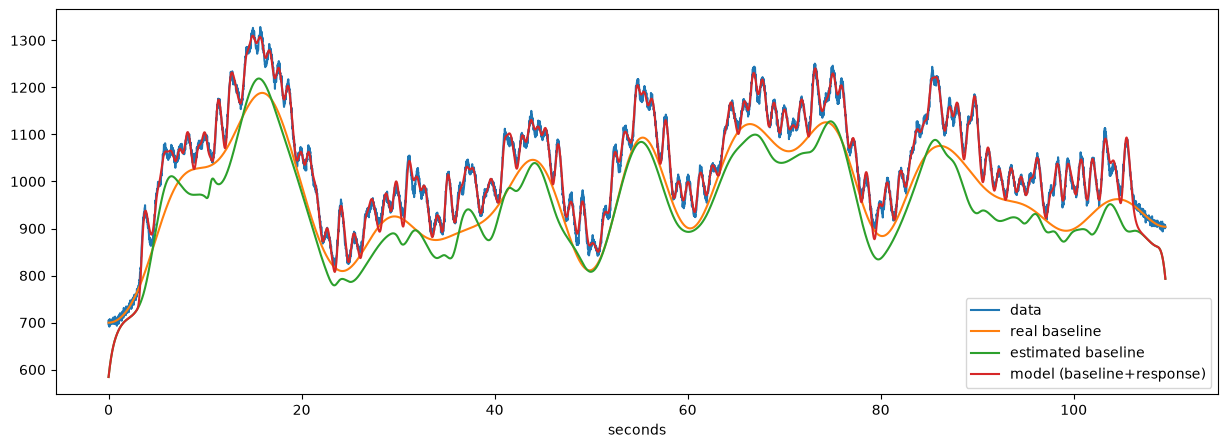

In [10]:
plt.figure(figsize=(15, 5))
plt.plot(d.tx/1000, d["left", "pupil"], label="data")
plt.plot(d.tx/1000, real_baseline, label="real baseline")
plt.plot(d.tx/1000, d["left", "baseline"], label="estimated baseline")
plt.plot(d.tx/1000, d["left", "baseline"] + d["left", "response"], label="model (baseline+response)")
plt.xlabel("seconds")
plt.legend();

The estimated baseline is more wiggly than the real one but gives a considerably better estimate than the traditional method. The overall fit of the model is excellent (which is to be expected for simulated data).

We can quantify how well the baseline estimation works relative to the traditional method by comparing both to the "ground truth" which is available for simulated data. We get the real and estimated baseline at each event onset with `stat_per_event()`:

In [11]:
# store the real baseline as a variable so that we can use stat_per_event()
d.data["left_realbaseline"] = real_baseline

at_onset = (0, 1000/fs) * u.ms   # one sample at the event onset
real_baseline_ev = d.stat_per_event(event_select="event", interval=at_onset)["left_realbaseline"]
novel_baseline = d.stat_per_event(event_select="event", interval=at_onset)["left_baseline"]
novel_response = d.params["response"]["left"]["coef"]

traditional_baseline = baseline
traditional_response = response

and compare them by means of the correlation between the estimated and the real values:

In [12]:
print("Traditional method:")
print("Baseline: Corr(trad, real) =", scipy.stats.pearsonr(traditional_baseline, real_baseline_ev)[0])
print("Response: Corr(trad, real) =", scipy.stats.pearsonr(traditional_response, real_response_coef)[0])
print("\nNovel method:")
print("Baseline: Corr(nov, real) =", scipy.stats.pearsonr(novel_baseline, real_baseline_ev)[0])
print("Response: Corr(nov, real) =", scipy.stats.pearsonr(novel_response, real_response_coef)[0])

Traditional method:
Baseline: Corr(trad, real) = 0.9552617927538912
Response: Corr(trad, real) = 0.43811540405889726

Novel method:
Baseline: Corr(nov, real) = 0.9754659627521309
Response: Corr(nov, real) = 0.6281775206841139


The correlations are higher for the novel method than for the traditional method. More detailed simulation studies are reported in [this notebook](symp_talk_uit2019.ipynb).

The parameters of the baseline estimation are described in the API documentation of `pp.baseline_envelope_iter_bspline()` and, in more detail, in [this notebook](symp_talk_uit2019.ipynb).

The parameters of the response estimation are described in the API documentation of `pp.pupil_response()`.